# 22 — Parameter estimation of binary black holes: CNN regression against bank MLE and grid posterior

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 25: the second half of "identify the mergers and predict their parameters". For IMRPhenomD signals injected in real test noise it estimates the chirp mass M_c, the total mass M, the mass ratio q and the merger time with three estimators and compares accuracy and calibration:

1. **Bank MLE** — best template of a 203-template IMR bank (29 total masses × 7 mass ratios, non-spinning, face-on), the frequentist estimator;
2. **Bayesian grid posterior** — the same bank cube with analytic amplitude marginalisation (σ_ρ = 10), flat prior on the grid and on the merger time; posterior mean and 68 % credible interval;
3. **CNN regression** — two 1-D CNNs (the project CNN with a global-max-pooling head, which discards the position, and the same trunk with a position-aware flatten head) with a heteroscedastic Gaussian head (mean and log-variance of the four standardised targets), trained with fresh IMR injections (SNR 6–20) on the training chunks, evaluated on the held-out library and test chunks.

Metrics per SNR: median fractional error of M_c and M, rms error of the merger time, and the empirical coverage of the nominal 68 % intervals (calibration).

**What it does not do.** The bank and the posterior assume non-spinning, face-on signals while the injected library has aligned spins and random inclination, so their model is *mismatched* (this favours the CNN, which was trained on the true family); the mass-ratio and spin degeneracy limit what any estimator can do; this is not a full Bayesian PE (no nested sampling, no sky position, one detector), see extension 35.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time, json, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import logsumexp
import seq_models as sm
import imr_tools as it
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
rng = np.random.default_rng(22)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("train", "val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1 = {sp: np.stack([CH[i]["S1"] for i in ID[sp]]) for sp in V}
LIB = {"imr": g.imr_library("train"), "imr_test": g.imr_library("test")}
mchirp = lambda M, q: M * q ** 0.6 / (1 + q) ** 1.2
TNAMES = ["mc", "mtot", "q", "tmerge"]
def targets(kind, p): lib = LIB[kind]; i = p["lib"]; return np.column_stack([lib["mc"][i], lib["mtot"][i], lib["q"][i], p["tc"] + p["t0"]])

## 1. CNN with a heteroscedastic Gaussian head (fresh injections, cached weights)

In [2]:
NOUT = 4
def build_flat(seed=0, nout=8):
    # same convolutional trunk as the project CNN, but the head keeps the POSITION (flatten) instead of global max pooling: needed for the merger time
    tf.keras.utils.set_random_seed(seed)
    return keras.Sequential([L.Input((g.NWIN, 1)),
        L.Conv1D(16, 15, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Conv1D(32, 9, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Conv1D(64, 5, padding="same"), L.BatchNormalization(), L.ReLU(), L.MaxPool1D(4),
        L.Flatten(), L.Dense(64, activation="relu"), L.Dropout(0.2), L.Dense(nout)])
def make_set(kind, split, n, snr, r, noise_idx=None):
    p = g.draw_params(kind, r, n); i = r.choice(len(V[split]), n, replace=noise_idx is None) if noise_idx is None else noise_idx
    snr = np.broadcast_to(np.asarray(snr, float), (n,)); ser, _, _ = g.inject(V[split][i], kind, snr, r, S1[split][i], params=p)
    return ser, targets(kind, p), ID[split][i], snr
Y0 = targets("imr", g.draw_params("imr", np.random.default_rng(0), 4000)); MU, SD = Y0.mean(0), Y0.std(0)
Xv, Yv, _, _ = make_set("imr", "val", 4000, np.random.default_rng(1).uniform(6, 20, 4000), np.random.default_rng(2))
class NLL(keras.losses.Loss):
    def call(self, y, out):
        mu, lv = out[:, :NOUT], tf.clip_by_value(out[:, NOUT:], -8, 4); return tf.reduce_mean(0.5 * (lv + (y - mu) ** 2 * tf.exp(-lv)), axis=-1)
def train(tag, builder):
    fn = os.path.join(sm.MODELS, f"v22_{tag}.weights.h5"); hf = fn.replace(".weights.h5", "_hist.json"); net = builder()
    net.compile(keras.optimizers.AdamW(keras.optimizers.schedules.CosineDecay(0.0, 25 * 128, alpha=0.02, warmup_target=2e-3, warmup_steps=256), weight_decay=1e-4), NLL())
    if os.path.exists(fn): net.load_weights(fn); return net, json.load(open(hf))
    r = np.random.default_rng(3); H = dict(loss=[], val_loss=[]); best, bw = np.inf, None
    for ep in range(25):
        n = len(V["train"]); X, Y, _, _ = make_set("imr", "train", n, r.uniform(6, 20, n), r)
        h = net.fit(sm.clip(X)[..., None], (Y - MU) / SD, validation_data=(sm.clip(Xv)[..., None], (Yv - MU) / SD), epochs=1, batch_size=128, verbose=0)
        l, vl = float(h.history["loss"][0]), float(h.history["val_loss"][0]); H["loss"].append(l); H["val_loss"].append(vl); print(f"{tag} ep {ep + 1:2d} loss {l:.3f} val {vl:.3f}", flush=True)
        if vl < best: best, bw = vl, net.get_weights()
    net.set_weights(bw); net.save_weights(fn); json.dump(H, open(hf, "w")); return net, H
NETS, HISTS = {}, {}
NETS["CNN (max-pool head)"], HISTS["CNN (max-pool head)"] = train("imr_regression", lambda: sm.build_cnn(seed=0, nout=2 * NOUT))
NETS["CNN (position-aware head)"], HISTS["CNN (position-aware head)"] = train("imr_regression_flat", lambda: build_flat(0, 2 * NOUT))
def cnn_predict(net, x):
    o = net.predict(sm.clip(x)[..., None], verbose=0, batch_size=512); mu = o[:, :NOUT] * SD + MU; sig = np.exp(0.5 * np.clip(o[:, NOUT:], -8, 4)) * SD; return mu, sig
HIST = {k: v for k, v in HISTS["CNN (position-aware head)"].items()}
print({k: round(min(h["val_loss"]), 3) for k, h in HISTS.items()}, "best validation NLL")

imr_regression_flat ep  1 loss 5.716 val 0.484


imr_regression_flat ep  2 loss 0.440 val 0.390


imr_regression_flat ep  3 loss 0.347 val 0.284


imr_regression_flat ep  4 loss 0.371 val 1.067


imr_regression_flat ep  5 loss 0.715 val 0.321


...

imr_regression_flat ep 22 loss 0.080 val 0.015


imr_regression_flat ep 23 loss 0.071 val 0.008


imr_regression_flat ep 24 loss 0.071 val 0.016


imr_regression_flat ep 25 loss 0.066 val 0.005


{'CNN (max-pool head)': 0.115, 'CNN (position-aware head)': 0.005} best validation NLL


## 2. Bank MLE and Bayesian grid posterior (203 templates)

In [3]:
MT = tuple(np.arange(30, 100.1, 2.5)); QS = tuple(np.linspace(0.25, 1.0, 7))
BANK = {i: it.IMRBank(CH[i]["S1"], mtots=MT, qs=QS) for i in CH}
GM = BANK[0].f0; GQ = BANK[0].Q; GMC = mchirp(GM, GQ); TAUS = np.arange(int(0.15 * g.NWIN), int(0.85 * g.NWIN)) / g.NWIN
S2 = 100.0
def bank_estimates(ser, cid):
    out = np.zeros((len(ser), 3, 4)); X = g.to_bins(ser)            # [mle, post mean, post std] x (mc, mtot, q, tmerge); plus 68% interval handled separately
    lo = np.zeros((len(ser), 4)); hi = np.zeros((len(ser), 4))
    for c in np.unique(cid):
        idx = np.where(cid == c)[0]
        for a in range(0, len(idx), 40):
            ii = idx[a:a + 40]; o = BANK[c].scan(X[ii], return_cube=True); cube = o["cube"].astype(np.float64)       # (b, nT, ntau)
            lnl = 0.5 * cube * S2 / (1 + S2); lt = logsumexp(lnl, axis=2); lt -= logsumexp(lt, axis=1, keepdims=True); wt = np.exp(lt)           # posterior over templates
            ltau = logsumexp(lnl, axis=1); ltau -= logsumexp(ltau, axis=1, keepdims=True); wtau = np.exp(ltau)
            j = lt.argmax(1); jt = np.array([cube[b, j[b]].argmax() for b in range(len(ii))])
            vals = np.stack([GMC, GM, GQ], 1)                                                              # (nT, 3)
            for k in range(3):
                m = wt @ vals[:, k]; s = np.sqrt(np.maximum(wt @ vals[:, k] ** 2 - m ** 2, 0)); out[ii, 1, k] = m; out[ii, 2, k] = s; out[ii, 0, k] = vals[j, k]
                for b, (w, vv) in enumerate(zip(wt, [vals[:, k]] * len(ii))):
                    o_ = np.argsort(vv); cw = np.cumsum(w[o_]); lo[ii[b], k] = vv[o_][np.searchsorted(cw, 0.16)]; hi[ii[b], k] = vv[o_][min(np.searchsorted(cw, 0.84), len(o_) - 1)]
            out[ii, 0, 3] = TAUS[jt]; m = wtau @ TAUS; out[ii, 1, 3] = m; out[ii, 2, 3] = np.sqrt(np.maximum(wtau @ TAUS ** 2 - m ** 2, 0))
            for b in range(len(ii)):
                cw = np.cumsum(wtau[b]); lo[ii[b], 3] = TAUS[np.searchsorted(cw, 0.16)]; hi[ii[b], 3] = TAUS[min(np.searchsorted(cw, 0.84), len(TAUS) - 1)]
    return out, lo, hi

## 3. Test: held-out IMR library in test noise

In [4]:
SNRS = [8, 10, 12, 16, 20]; NINJ = 300; fn = os.path.join(g.CACHE, "stats22.pkl")
if os.path.exists(fn):
    RES = pickle.load(open(fn, "rb"))
else:
    RES = {}; t0_ = time.time()
    for s in SNRS:
        ser, Y, cid, _ = make_set("imr_test", "test", NINJ, float(s), np.random.default_rng(100 + s))
        be, lo, hi = bank_estimates(ser, cid); RES[s] = dict(Y=Y, bank=be, lo=lo, hi=hi)
        for nm, nt in NETS.items(): RES[s][nm] = cnn_predict(nt, ser); print("snr", s, "%.0f s" % (time.time() - t0_), flush=True)
    pickle.dump(RES, open(fn, "wb"))
rows = []
for s, d in RES.items():
    Y = d["Y"]; est = {"bank MLE": d["bank"][:, 0, :], "posterior mean": d["bank"][:, 1, :], **{nm: d[nm][0] for nm in NETS}}
    for name, E in est.items():
        for k, tn in enumerate(TNAMES):
            err = E[:, k] - Y[:, k]; rel = np.abs(err) / Y[:, k] if tn != "tmerge" else np.abs(err)
            rows.append(dict(snr=s, estimator=name, param=tn, median_abs_err=float(np.median(rel)) * (1e3 if tn == "tmerge" else 1.0), rms=float(np.sqrt(np.mean(err ** 2)))))
ERR = pd.DataFrame(rows)
print("median |relative error| of the chirp mass and of the total mass; median |error| of the merger time [ms]")
ERR.pivot_table(index=["param", "estimator"], columns="snr", values="median_abs_err").round(3)

snr 8 4 s


snr 8 4 s


snr 10 7 s


snr 10 7 s


snr 12 11 s


...

snr 16 14 s


snr 20 17 s


snr 20 17 s


median |relative error| of the chirp mass and of the total mass; median |error| of the merger time [ms]


snr                                   8       10      12      16      20
param  estimator                                                        
mc     CNN (max-pool head)         0.132   0.120   0.101   0.084   0.088
       CNN (position-aware head)   0.172   0.150   0.135   0.130   0.107
       bank MLE                    0.075   0.073   0.068   0.076   0.067
       posterior mean              0.067   0.073   0.068   0.069   0.063
mtot   CNN (max-pool head)         0.133   0.102   0.094   0.085   0.080
       CNN (position-aware head)   0.164   0.150   0.135   0.132   0.107
       bank MLE                    0.079   0.074   0.075   0.084   0.072
       posterior mean              0.077   0.073   0.077   0.080   0.074
q      CNN (max-pool head)         0.266   0.277   0.276   0.253   0.282
       CNN (position-aware head)   0.265   0.278   0.275   0.260   0.287
       bank MLE                    0.306   0.281   0.307   0.286   0.244
       posterior mean              0.249   0.252   0.242   0.235   0.211
tmerge CNN (max-pool head)        84.876  81.734  73.444  90.041  87.040
       CNN (position-aware head)  36.983  27.739  20.833  19.085  14.549
       bank MLE                    1.626   1.482   1.307   1.255   1.182
       posterior mean              1.292   1.018   1.126   1.146   1.088

In [5]:
# calibration: fraction of truths inside the nominal 68 % interval
cov = []
for s, d in RES.items():
    Y = d["Y"]
    for k, tn in enumerate(TNAMES):
        cov.append(dict(snr=s, param=tn, estimator="posterior (grid)", coverage68=float(np.mean((Y[:, k] >= d["lo"][:, k]) & (Y[:, k] <= d["hi"][:, k]))), width=float(np.median(d["hi"][:, k] - d["lo"][:, k]))))
        for nm in NETS:
            mu, sg = d[nm]; z = np.abs(mu[:, k] - Y[:, k]) / sg[:, k]; cov.append(dict(snr=s, param=tn, estimator=nm, coverage68=float(np.mean(z <= 1.0)), width=float(np.median(2 * sg[:, k]))))
COV = pd.DataFrame(cov); COV.pivot_table(index=["param", "estimator"], columns="snr", values="coverage68").round(2)

snr                                 8     10    12    16    20
param  estimator                                              
mc     CNN (max-pool head)        0.72  0.67  0.73  0.74  0.72
       CNN (position-aware head)  0.75  0.73  0.78  0.78  0.81
       posterior (grid)           0.32  0.28  0.24  0.18  0.12
mtot   CNN (max-pool head)        0.70  0.78  0.80  0.80  0.76
       CNN (position-aware head)  0.65  0.67  0.75  0.77  0.82
       posterior (grid)           0.28  0.19  0.18  0.11  0.09
q      CNN (max-pool head)        0.64  0.58  0.61  0.62  0.54
       CNN (position-aware head)  0.63  0.57  0.62  0.62  0.56
       posterior (grid)           0.67  0.59  0.51  0.41  0.35
tmerge CNN (max-pool head)        0.62  0.60  0.66  0.57  0.59
       CNN (position-aware head)  0.67  0.74  0.76  0.78  0.83
       posterior (grid)           0.50  0.50  0.40  0.32  0.25

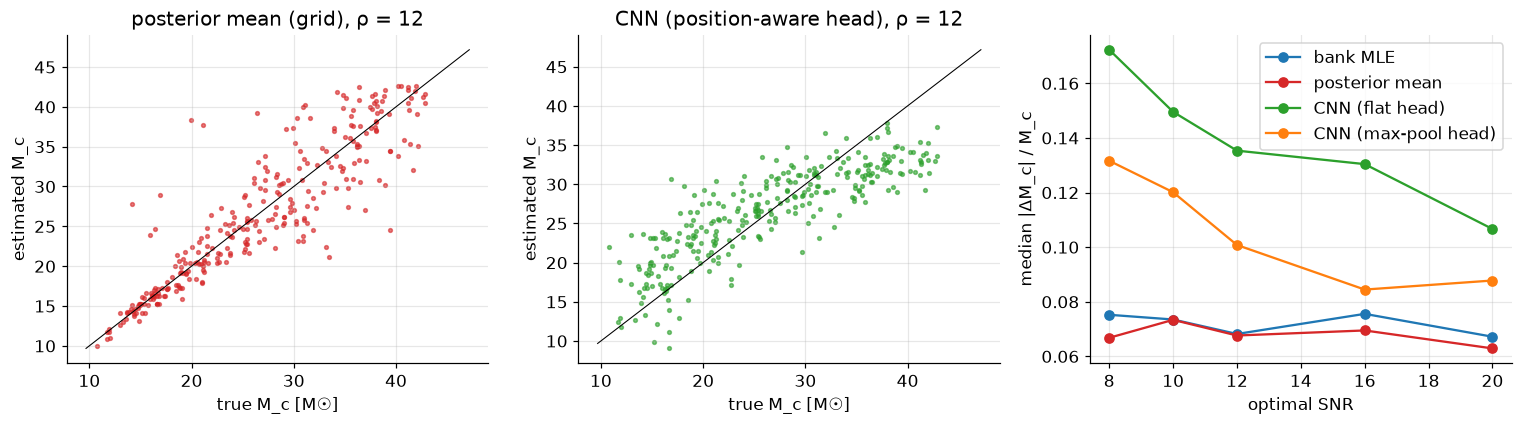

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
d = RES[12]; Y = d["Y"]
for a, (name, E, c) in zip(ax[:2], (("posterior mean (grid)", d["bank"][:, 1, :], g.COLORS["bayes"]), ("CNN (position-aware head)", d["CNN (position-aware head)"][0], "C2"))):
    a.scatter(Y[:, 0], E[:, 0], s=6, color=c, alpha=.6); lim = [Y[:, 0].min() * .9, Y[:, 0].max() * 1.1]; a.plot(lim, lim, "k-", lw=.7); a.set_xlabel("true M_c [M☉]"); a.set_ylabel("estimated M_c"); a.set_title(f"{name}, ρ = 12")
for est, c, lab in (("bank MLE", g.COLORS["freq"], "bank MLE"), ("posterior mean", g.COLORS["bayes"], "posterior mean"), ("CNN (position-aware head)", "C2", "CNN (flat head)"), ("CNN (max-pool head)", "C1", "CNN (max-pool head)")):
    e = ERR[(ERR.estimator == est) & (ERR.param == "mc")].sort_values("snr"); ax[2].plot(e.snr, e.median_abs_err, marker="o", color=c, label=lab)
ax[2].set_xlabel("optimal SNR"); ax[2].set_ylabel("median |ΔM_c| / M_c"); ax[2].legend(); fig.tight_layout(); g.savefig(fig, "fig22_parameter_estimation"); plt.show()
g.save_json(dict(errors=ERR.to_dict("records"), coverage=COV.to_dict("records"), cnn_best_val_nll={k: float(min(h["val_loss"])) for k, h in HISTS.items()}), "22_summary.json")

## Output and next step

`results/22_summary.json`, `figures/fig22_parameter_estimation`, cached weights `cache/models/v22_imr_regression.*`. Next: the remaining extensions of the backlog.